# Hypotheses, features and information timing

Can changing future observations alter earlier fits, scores or eligible holdings?

This notebook reviews saved retrospective evidence. New descriptive calculations are post-study analysis, not new strategy selection or an untouched test.

In [1]:
from pathlib import Path
import json,sys,math,statistics
r=Path.cwd()
if not (r/'artifacts/research').exists(): r=r.parent
sys.path.insert(0,str(r/'src'));sys.path.insert(0,str(r))
from scripts.review_visuals import table,figure,lines,bars
if 'display_bundle' not in globals():
 from IPython.display import display
 def display_bundle(data): display(data,raw=True)
b=json.loads((r/'artifacts/research/public_bundle.json').read_text());a=b['analysis']
p=json.loads((r/'artifacts/review/polish.json').read_text());chosen=b['selected']
print('Saved test:',b['as_of'],'Selected:',chosen,'Post-study review:',p['review_date'])

Saved test: 2025-12-31 Selected: stumps_24 Post-study review: 2026-11-25


## Feature contract

Five technical/liquidity features are known by signal close.

In [2]:
display_bundle(table(['Feature','Definition'],list(a['feature_register'].items())))

Feature,Definition
momentum_21,21-session trailing distribution-inclusive wealth return
momentum_63,63-session trailing distribution-inclusive wealth return
volatility_20,Sample standard deviation of 20 daily wealth returns; not annualised
drawdown_63,"Current wealth divided by maximum wealth in 64 observations, minus one"
log_dollar_volume_20,log(1 + trailing 20-session mean raw close × capacity-proxy volume)


## Maturity receipts

Only matured forward labels, with a session gap, enter each expanding fit.

In [3]:
assert all(x['max_label_end']<x['signal_date']<x['fill_date'] for x in b['fits']);display_bundle(table(['Signal','Latest label end','Intended fill','Train rows'],[[x['signal_date'],x['max_label_end'],x['fill_date'],x['fit_rows']] for x in b['fits'][::6]]))

Signal,Latest label end,Intended fill,Train rows
2022-12-30,2022-12-28,2023-01-03,12807
2023-06-30,2023-06-28,2023-07-03,13923
2023-12-29,2023-12-27,2024-01-02,15057
2024-06-28,2024-06-26,2024-07-01,16173
2024-12-31,2024-12-27,2025-01-02,17325
2025-06-30,2025-06-26,2025-07-01,18423


## Selected-model mutation challenge

Mutate future prices and volume after a cutoff. Compare the 24-stump fit, earlier scores, top-three choices and an eligible pre-cutoff ledger.

In [4]:
import importlib.util
spec=importlib.util.spec_from_file_location('temporal',r/'tests/test_temporal.py');t=importlib.util.module_from_spec(spec);spec.loader.exec_module(t)
t.test_future_price_changes_cannot_change_earlier_features_or_ridge_predictions();t.test_future_market_mutation_preserves_selected_stump_fit_scores_and_holdings()
display_bundle(table(['Challenge','Result'],[['Ridge / earlier features','Pass'],['Selected stump fit / scores / choices / holdings','Pass']]))

Challenge,Result
Ridge / earlier features,Pass
Selected stump fit / scores / choices / holdings,Pass


## Expanding sample

Growing training rows are a receipt of past information, not validation of the provider vintage.

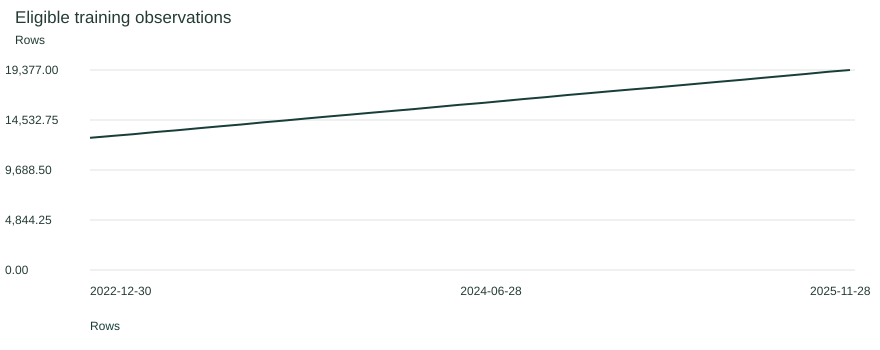

In [5]:
display_bundle(figure(lines('Eligible training observations',[x['signal_date'] for x in b['fits']],{'Rows':[x['fit_rows'] for x in b['fits']]},'Rows')))

## Interpretation

Both ridge and selected-stump perturbation checks pass. This constrains direct computational look-ahead in the tested cases; it does not remove retrospective source-revision bias.